In [11]:
from cProfile import label

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from holoviews.plotting.bokeh.styles import marker
from matplotlib import rcParams
rcParams['font.sans-serif'] = ['STHeiti']
import seaborn as sns
df = pd.read_csv(
    "data/raw/Sample - Superstore.csv",
    encoding="windows-1252",
    dtype={"Postal Code": "string"},
)
print(f"行数与列数:{df.shape}")
print(f"缺失值总数:{df.isna().sum()}")
print(f"完全重复的行数:{df.duplicated().sum()}") #完全重复行数为0 无须进行去除操作
df.info()
df.head(5)

行数与列数:(9994, 21)
缺失值总数:Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64
完全重复的行数:0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Cou

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [15]:
df['Ship Date'] = pd.to_datetime(df['Ship Date'])
df['Order Date'] = pd.to_datetime(df['Order Date']) #修正日期格式
df['Postal Code'] = df['Postal Code'].astype(str)
# 逻辑检验 检查有没有“发货日期早于下单日期”的异常订单
invalid_dates = df[df['Ship Date'] < df['Order Date']]
print(f"异常订单数:{len(invalid_dates)}")

异常订单数:0


In [16]:
# 构造新指标
# 1. 从下单日期里提取“年份”和“月份”，方便以后看时间趋势
df['Order Year'] = df['Order Date'].dt.year
df['Order Month'] = df['Order Date'].dt.month
df['Year-Month'] = df['Order Date'].dt.to_period('M').astype(str)
# 2. 计算发货耗时（天）：发货日期 - 下单日期
df['Shipping Days'] = (df['Ship Date'] - df['Order Date']).dt.days
# 3. 计算单笔利润率（Profit Margin = 利润 / 销售额）
# 加上 np.where 防止极少数销售额为 0 时除以 0 报错
df['Profit Margin'] = np.where(df['Sales'] != 0, df['Profit'] / df['Sales'], 0)

In [19]:
# 折扣分组
df['Discount Band'] = pd.cut(
    df['Discount'],
    bins=[-0.01,0,0.2,0.4,1.0],
    labels=['无折扣','低折扣','中折扣','高折扣']
)

In [56]:
# 核心数据
total_sales = df['Sales'].sum()
total_profit = df['Profit'].sum()
overall_margin = total_profit / total_sales
total_quantity = df['Quantity'].sum()
total_orders = df['Order ID'].nunique() # unique去重订单数
total_customers = df['Customer ID'].nunique()
loss_rate = (df['Profit'] < 0).mean() * 100
print(f"总销售额:{total_sales:.2f}")
print(f"总利润:{total_profit:.2f}")
print(f"整理利润率:{overall_margin:.2%}")
print(f"总销量:{total_quantity:.2f}")
print(f"总订单数:{total_orders:.2f}")
print(f"总客户数:{total_customers:.2f}")
print(f"亏损记录占比:{loss_rate:.2f}%")


总销售额:2297200.86
总利润:286397.02
整理利润率:12.47%
总销量:37873.00
总订单数:5009.00
总客户数:793.00
亏损记录占比:18.72%


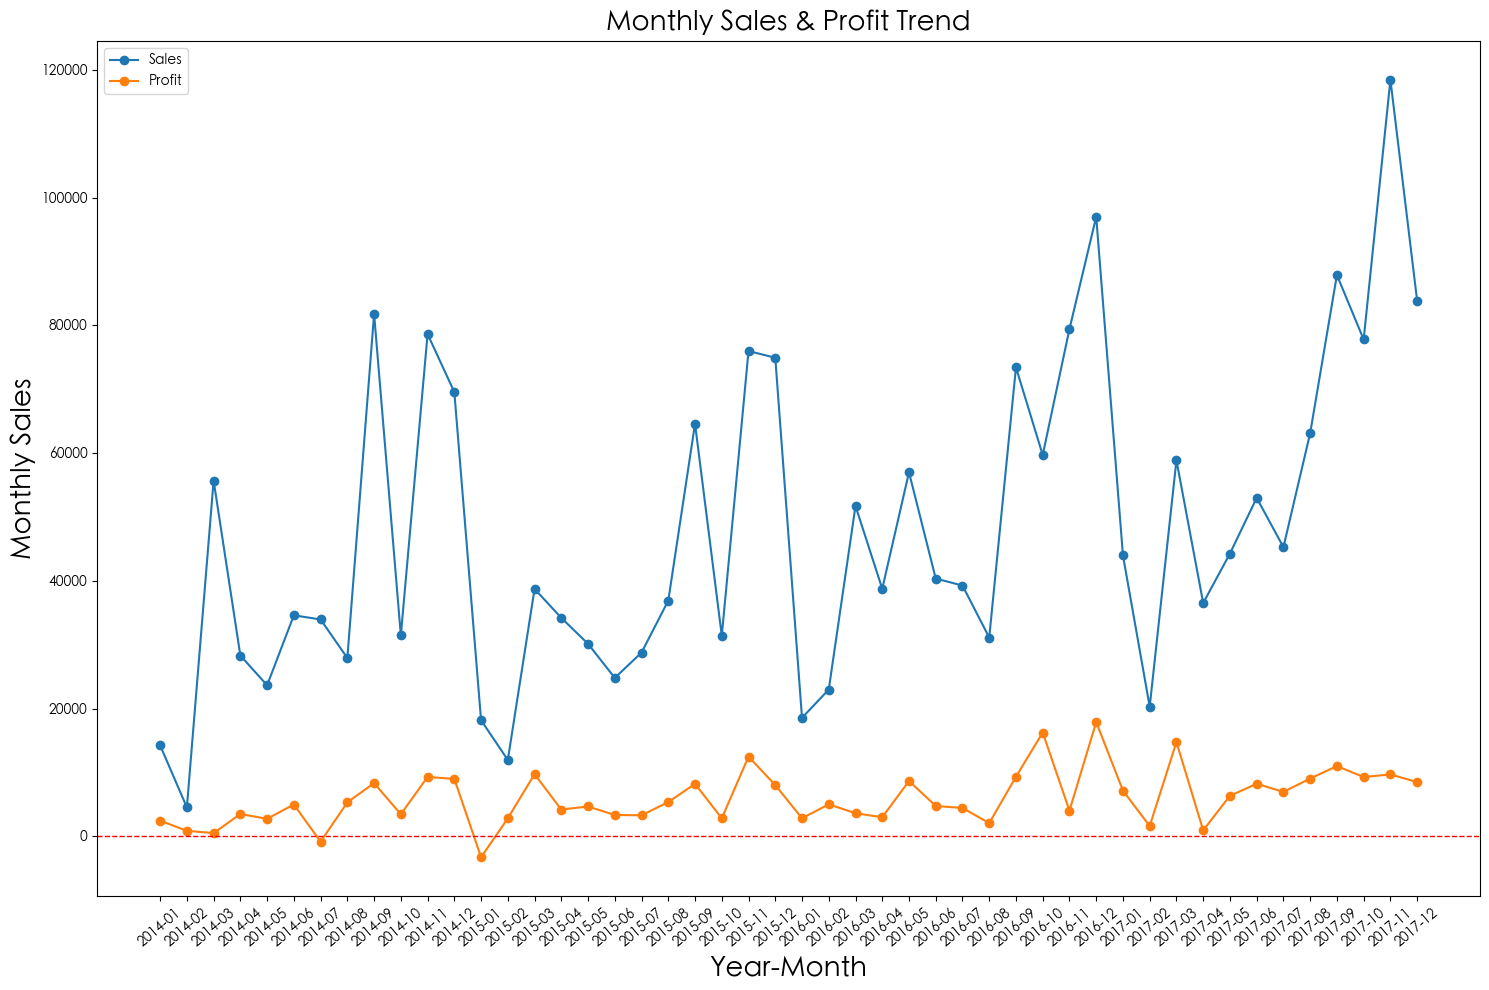

In [45]:
# 销售额和利润随月份的变化
monthly = df.groupby('Year-Month',as_index=False).agg({
    'Sales': 'sum',
    'Profit': 'sum',
})
plt.figure(figsize = (15,10))
plt.plot(monthly['Year-Month'],monthly['Sales'],marker='o',label='Sales')
plt.plot(monthly['Year-Month'],monthly['Profit'],marker='o',label='Profit')
plt.axhline(0, color='red', linestyle='--', linewidth=1)
plt.title('Monthly Sales & Profit Trend',fontsize = 20)
plt.xlabel('Year-Month',fontsize = 20)
plt.ylabel('Monthly Sales',fontsize = 20)
plt.xticks(fontsize = 10,rotation = 40)
plt.legend()
plt.tight_layout()
plt.show()

--- 按产品大类汇总 ---


,Category,Sales,Profit,Profit Margin (%)
2,Technology,836154.0330,145454.9481,17.395712
1,Office Supplies,719047.0320,122490.8008,17.035158
0,Furniture,741999.7953,18451.2728,2.486695


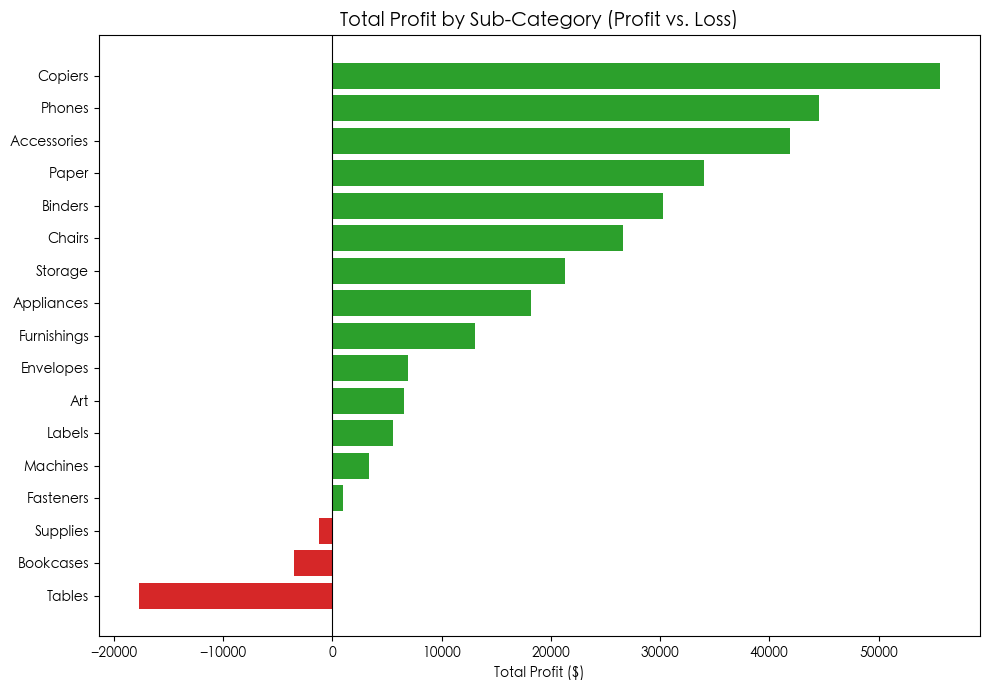

In [50]:
# 哪个大类&子类最赚钱
cat_summary = df.groupby('Category',as_index=False).agg({
    'Sales': 'sum',
    'Profit': 'sum',
})
cat_summary['Profit Margin (%)'] = (cat_summary['Profit'] / cat_summary['Sales']) * 100
print("--- 按产品大类汇总 ---")
display(cat_summary.sort_values('Profit', ascending=False))
# 按子类画利润对比图（正利润绿色，负利润红色）
sub_cat = df.groupby('Sub-Category')[['Sales', 'Profit']].sum().sort_values('Profit')
plt.figure(figsize=(10, 7))
colors = ['#d62728' if x < 0 else '#2ca02c' for x in sub_cat['Profit']]
plt.barh(sub_cat.index, sub_cat['Profit'], color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Total Profit by Sub-Category (Profit vs. Loss)', fontsize=14, fontweight='bold')
plt.xlabel('Total Profit ($)')
plt.tight_layout()
plt.show()



,Records,Total_Sales,Total_Profit,Avg_Profit_Margin
Discount Band,,,,
无折扣,4798,1.087908e+06,320987.6032,34.016048
低折扣,3803,8.465222e+05,100785.4745,17.436785
中折扣,460,2.341379e+05,-35817.4655,-16.685544
高折扣,933,1.286323e+05,-99558.5905,-108.900322


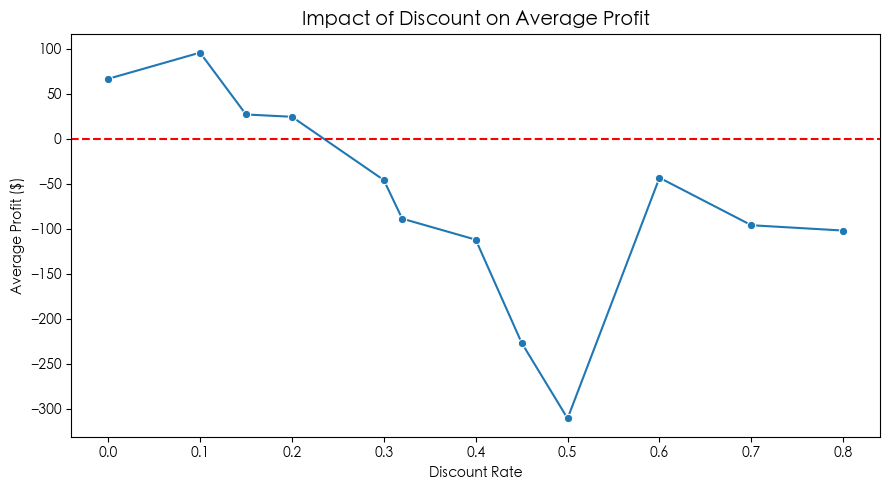

In [51]:
# 按折扣区间统计平均利润率与总利润
discount_summary = df.groupby('Discount Band', observed=False).agg(
    Records=('Order ID', 'count'),
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Avg_Profit_Margin=('Profit Margin', 'mean')
)
discount_summary['Avg_Profit_Margin'] = discount_summary['Avg_Profit_Margin'] * 100
display(discount_summary)

# 画折扣 vs 利润的散点/趋势图
plt.figure(figsize=(9, 5))
sns.lineplot(data=df, x='Discount', y='Profit', marker='o', errorbar=None)
plt.axhline(0, color='red', linestyle='--')
plt.title('Impact of Discount on Average Profit', fontsize=14, fontweight='bold')
plt.xlabel('Discount Rate')
plt.ylabel('Average Profit ($)')
plt.tight_layout()
plt.show()

--- 各大区销售与利润 ---


,Sales,Profit,Profit Margin (%)
Region,,,
West,725457.8245,108418.4489,14.944831
East,678781.2400,91522.7800,13.483399
South,391721.9050,46749.4303,11.934342
Central,501239.8908,39706.3625,7.921629


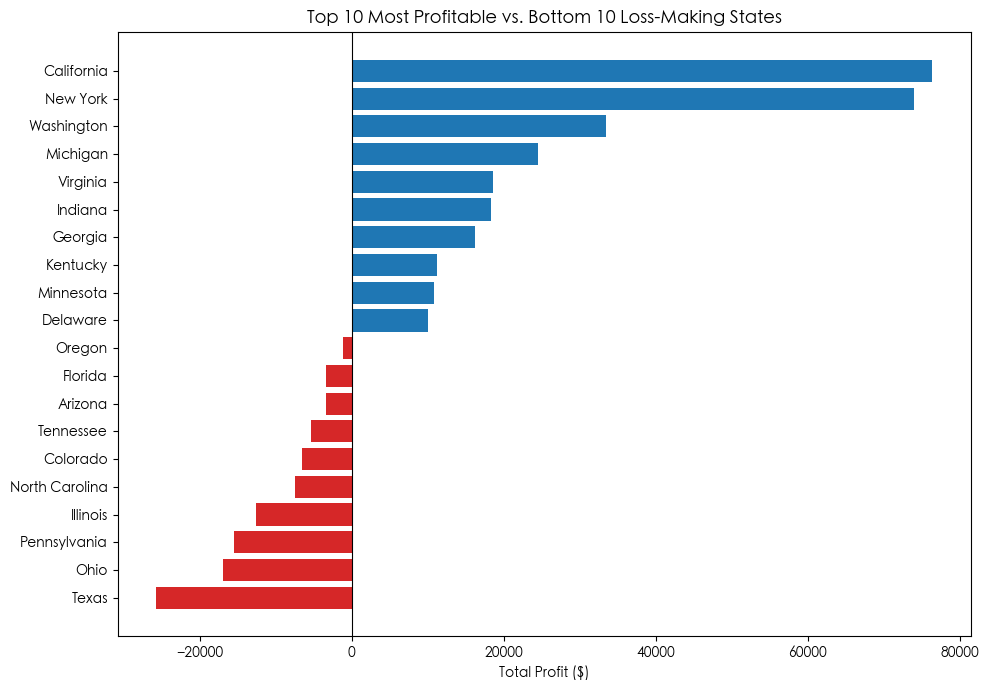

In [53]:
# 地区与州分析：找出最赚钱 Top 10 和最亏钱 Bottom 10 的州
region_summary = df.groupby('Region')[['Sales', 'Profit']].sum()
region_summary['Profit Margin (%)'] = (region_summary['Profit'] / region_summary['Sales']) * 100
print("--- 各大区销售与利润 ---")
display(region_summary.sort_values('Profit', ascending=False))

# 2. 最赚钱 Top 10 vs 最亏钱 Bottom 10 的州
state_profit = df.groupby('State')['Profit'].sum().sort_values()
top_bottom_states = pd.concat([state_profit.head(10), state_profit.tail(10)])

plt.figure(figsize=(10, 7))
colors = ['#d62728' if x < 0 else '#1f77b4' for x in top_bottom_states.values]
plt.barh(top_bottom_states.index, top_bottom_states.values, color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Top 10 Most Profitable vs. Bottom 10 Loss-Making States', fontsize=13, fontweight='bold')
plt.xlabel('Total Profit ($)')
plt.tight_layout()
plt.show()

In [54]:
# 客户群体与发货方式分析
# 客户群体分析
seg_summary = df.groupby('Segment')[['Sales', 'Profit']].sum()
seg_summary['Profit Margin (%)'] = (seg_summary['Profit'] / seg_summary['Sales']) * 100
print("--- 按客户群体汇总 ---")
display(seg_summary)

# 发货方式分析
ship_summary = df.groupby('Ship Mode').agg(
    Orders=('Order ID', 'nunique'),
    Avg_Shipping_Days=('Shipping Days', 'mean'),
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum')
)
print("\n--- 按发货方式汇总 ---")
display(ship_summary)

--- 按客户群体汇总 ---


,Sales,Profit,Profit Margin (%)
Segment,,,
Consumer,1.161401e+06,134119.2092,11.548050
Corporate,7.061464e+05,91979.1340,13.025506
Home Office,4.296531e+05,60298.6785,14.034269



--- 按发货方式汇总 ---


,Orders,Avg_Shipping_Days,Total_Sales,Total_Profit
Ship Mode,,,,
First Class,787,2.182705,3.514284e+05,48969.8399
Same Day,264,0.044199,1.283631e+05,15891.7589
Second Class,964,3.238046,4.591936e+05,57446.6354
Standard Class,2994,5.006535,1.358216e+06,164088.7875
